# 4 · Training on a GPU

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/shimmeringvoid/Qubic_Zero/blob/main/notebooks/04_train_on_a_gpu.ipynb)

This notebook trains the Qubic player. It wants a GPU: on Google Colab choose *Runtime → Change
runtime type → GPU* first; on any other machine it uses the CUDA device if there is one.

* **A run is a folder.** It holds the settings, a log, snapshots of the weights and a checkpoint.
  On Colab the folder is on your Google Drive, so it survives the session.
* **Stopping is safe at any time**, whether by the stop button, by the time limit below, or by Colab
  ending the session. Run the notebook again and training continues from the last checkpoint
  (one is written every ten minutes).
* **Several seeds** are several runs: change `RUN_NAME` and `SEED` and run the notebook again.
* **The last cell zips what to send back**: the log and the weights, a megabyte or so.

Nothing here is specific to Colab except the Google Drive cell. On a cloud machine or on your own
the same run is one command, `python -m qubic_zero.train --run-dir runs/qubic-seed-0 --seed 0 --hours 11`,
and `python -m qubic_zero.benchmark` is the speed test. Outside Colab, on a machine with a GPU, this
notebook keeps its runs in `runs/` at the top of the repository; that command puts them there too
when it is run from the top of the repository.

**The outputs stored below are not a training run.** They come from a machine without a GPU, on
which the notebook switches to tiny settings so that every cell can be tried in a minute.

In [1]:
# Only needed on Google Colab, which opens this notebook without the rest of the repository:
# fetch the repository and put its library on the path.  Anywhere else this cell does nothing.
import sys

if "google.colab" in sys.modules:
    import os
    import subprocess

    if not os.path.isdir("Qubic_Zero"):
        subprocess.run(["git", "clone", "-q", "--depth", "1", "https://github.com/shimmeringvoid/Qubic_Zero"], check=True)
    sys.path.insert(0, os.path.abspath("Qubic_Zero/src"))

In [2]:
RUN_NAME = "qubic-seed-0"     # one folder per run; another name starts another run
SEED = 0                      # decides the initial weights and every random choice of the run
HOURS = 11.0                  # stop and checkpoint after this long (Colab ends sessions after about 12 hours)
POSITIONS = 5_000_000         # length of the whole run: positions searched in self-play

In [3]:
import json
import os
import tempfile
import time
import zipfile
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import torch

from qubic_zero import plotting as qp
from qubic_zero.benchmark import hours_for, measure
from qubic_zero.evaluate import standard_evaluators
from qubic_zero.net import count_weights
from qubic_zero.train import PRESETS, Config, Trainer, zip_run

qp.use_style()
ON_COLAB = "google.colab" in sys.modules
HAS_GPU = torch.cuda.is_available()

if ON_COLAB:
    from google.colab import drive

    drive.mount("/content/drive")
    RUNS = Path("/content/drive/MyDrive/Qubic_Zero/runs")
elif HAS_GPU:
    RUNS = Path(os.environ.get("QUBIC_ZERO_RUNS", qp.repo_root() / "runs"))
else:
    RUNS = Path(tempfile.mkdtemp())      # a smoke run: nothing worth keeping

if HAS_GPU:
    config = PRESETS["4x4x4"].replace(seed=SEED, positions=POSITIONS)
    evaluation = dict(n_games=200, per_kind=200)
else:
    config = Config(game="4x4x4", width=32, depth=2, n_games=32, n_sims=8, memory=20_000, batch_size=64, warmup=500,
                    positions=32 * 90, seed=SEED, report_every=15, evaluate_every=45, snapshot_every=45)
    evaluation = dict(n_games=20, per_kind=40)
    HOURS = 0.05

RUN_DIR = RUNS / RUN_NAME
print("GPU:", torch.cuda.get_device_name(0) if HAS_GPU else "none, so this is a smoke run with tiny settings")
print("the run lives in", RUN_DIR, "(continuing it)" if (RUN_DIR / "checkpoint.pt").exists() else "(new)")
print(f"{config.n_games} games side by side, {config.n_sims} simulations per move, {config.positions:,} positions in all")

GPU: none, so this is a smoke run with tiny settings
the run lives in /tmp/tmpc97qcwcu/qubic-seed-0 (new)
32 games side by side, 8 simulations per move, 2,880 positions in all


## How long will it take?

Training time goes into the tree searches of self-play (one call of the network per simulation,
for all games at once) and into the gradient steps. The cell below times both on this machine
for two minutes, with a fresh network, and scales the result to the length of the run.

The estimate is rough: games get longer or shorter as the network learns, and a trained
network grows deeper trees than a fresh one. It is good for telling one hour from ten.

In [4]:
speed = measure(config, seconds=120 if HAS_GPU else 12)
print(f"{speed['device']}: {speed['positions_per_second']:,.0f} positions searched per second, "
      f"{speed['evaluations_per_second']:,.0f} positions through the network per second, "
      f"{speed['steps_per_second']:.1f} gradient steps per second")
estimate = pd.DataFrame({"positions searched": [1_000_000, 5_000_000, 20_000_000]})
estimate["games (at 30 moves each)"] = estimate["positions searched"] // 30
estimate["hours on this machine"] = [hours_for(config, speed, n) for n in estimate["positions searched"]]
print(f"this run ({config.positions:,} positions): about {hours_for(config, speed):.1f} hours")
estimate.style.format({"positions searched": "{:,}", "games (at 30 moves each)": "{:,}", "hours on this machine": "{:.1f}"}).hide(axis="index")

CPU, 2 threads: 1,221 positions searched per second, 10,729 positions through the network per second, 108.9 gradient steps per second
this run (2,880 positions): about 0.0 hours


positions searched,games (at 30 moves each),hours on this machine
"1,000,000","33,333",0.4
"5,000,000","166,666",1.9
"20,000,000","666,666",7.7


## Train

A line is printed per report: positions searched, games finished, hours of training, the two
losses (policy and value) and how the self-play games went since the last report. Every so
often a second line gives scores, for the network alone and for the network with its tree
search: on the three kinds of tactical positions with exact answers (`win/block/force`, see
notebook 1) and in games against the rule player from both sides. The log file has every number.

The cell can be interrupted and run again.

In [5]:
trainer = Trainer(config, RUN_DIR)
trainer.evaluators = standard_evaluators(trainer.game, config, **evaluation)
print(f"{count_weights(trainer.net):,} weights on {trainer.device}")
started = time.perf_counter()
trainer.run(hours=HOURS)
done = trainer.positions >= config.positions
print(f"\n{'finished' if done else 'stopped'} after {(time.perf_counter() - started) / 60:.1f} minutes in this session: "
      f"{trainer.positions:,} of {config.positions:,} positions, {trainer.games:,} games, {trainer.steps:,} gradient steps")

14,914 weights on cpu


         0 positions |        0 games |   0.00 h
            scored  network alone: win/block/force 2%/0%/0%, v. rule player 10% first, 5% second; with search: win/block/force 5%/0%/0%, v. rule player 10% first, 5% second


       480 positions |        1 games |   0.00 h | first player wins 0%, 12.0 moves a game


       960 positions |       21 games |   0.00 h | first player wins 50%, 23.0 moves a game


     1,440 positions |       43 games |   0.00 h | loss 3.932 + 0.606 | first player wins 36%, 26.0 moves a game
            scored  network alone: win/block/force 48%/0%/68%, v. rule player 70% first, 35% second; with search: win/block/force 90%/2%/20%, v. rule player 30% first, 40% second


     1,920 positions |       65 games |   0.00 h | loss 3.926 + 0.612 | first player wins 50%, 23.2 moves a game


     2,400 positions |       85 games |   0.00 h | loss 3.933 + 0.607 | first player wins 40%, 23.8 moves a game


     2,880 positions |      108 games |   0.00 h | loss 3.929 + 0.622 | first player wins 57%, 22.7 moves a game
            scored  network alone: win/block/force 70%/0%/70%, v. rule player 25% first, 30% second; with search: win/block/force 95%/8%/28%, v. rule player 50% first, 30% second



finished after 0.1 minutes in this session: 2,880 of 2,880 positions, 108 games, 130 gradient steps


## How is it doing?

The curves that matter are the ones against exact answers. `force` is the hard one: positions
in which a win can be forced with a chain of threats, several moves deep.

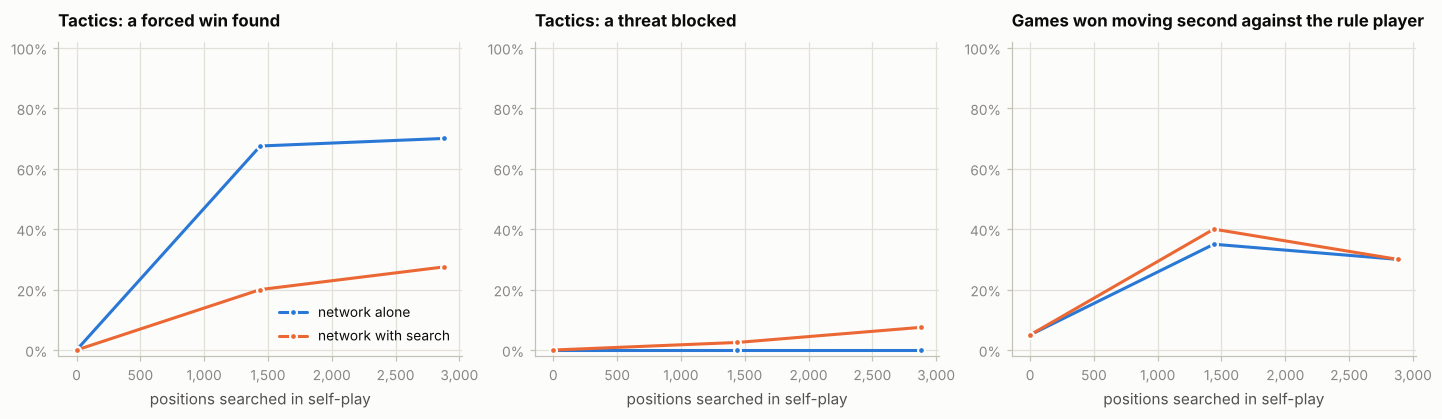

after 2,880 positions: forced wins found 70.0% (network alone) and 27.5% (with search); as first player against the rule player 50.0% won; as second 30.0%


In [6]:
log = qp.load_log(RUN_DIR)
scored = log.dropna(subset=["net_force"])
fig, axes = plt.subplots(1, 3, figsize=(13, 3.7))
panels = [("Tactics: a forced win found", "force"), ("Tactics: a threat blocked", "block"),
          ("Games won moving second against the rule player", "second_won")]
for ax, (title, key) in zip(axes, panels):
    ax.plot(scored["positions"], scored[f"net_{key}"], color=qp.SERIES[0], marker="o", ms=4.5, label="network alone")
    ax.plot(scored["positions"], scored[f"search_{key}"], color=qp.SERIES[1], marker="o", ms=4.5, label="network with search")
    ax.set(title=title, xlabel="positions searched in self-play", ylim=(-0.02, 1.02))
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
    ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v / 1e6:.1f}M" if v >= 1e6 else f"{v:,.0f}"))
axes[0].legend(loc="lower right")
plt.show()
last = scored.iloc[-1]
print(f"after {int(last['positions']):,} positions: forced wins found {last['net_force']:.1%} (network alone) and {last['search_force']:.1%} (with search); "
      f"as first player against the rule player {last['search_first_won']:.1%} won; as second {last['search_second_won']:.1%}")

## What to send back

The settings, the log and the weights, zipped next to the run's folder. On Colab the file is
also offered as a download. The command line writes the same file whenever it stops.

In [7]:
bundle = zip_run(RUN_DIR)
print(f"{bundle.name}: {bundle.stat().st_size / 1e6:.2f} MB, {len(zipfile.ZipFile(bundle).namelist())} files")
if ON_COLAB:
    from google.colab import files

    files.download(str(bundle))

qubic-seed-0.zip: 0.18 MB, 5 files
